# Lab 06 — NLP Foundations: Handwriting OCR Evaluation

**Objective.** Benchmark Tesseract on 89 labelled medicine-name images, test one controlled preprocessing pipeline, and classify the failures.

**Data.** `all_datasets/lab06-ocr-handwritten-prescription.zip`.

**Run.** From the course folder, run `cd all_experiments`, start Jupyter, open this notebook, and choose **Restart Kernel and Run All Cells**.

**Evidence.** Predictions, metrics, preprocessed images, and failure analysis in `results/lab06/`.

**Prerequisite.** Live OCR needs the Tesseract engine; if it is unavailable, the notebook clearly uses the validated predictions included with the course package.

**Workflow**

1. Validate the archive.
2. Run the raw-image OCR baseline.
3. Measure recognition quality.
4. Build one preprocessing pipeline.
5. Compare the two pipelines fairly.
6. Analyse the failures.


## Setup

In [3]:
import re
import shutil
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pytesseract
from IPython.display import display
from PIL import Image, ImageFile, ImageOps

ROOT = Path.cwd().parent
DATA = ROOT / "all_datasets"
RESULTS = ROOT / "results" / "lab06"
RESULTS.mkdir(parents=True, exist_ok=True)

# Accept mildly truncated photographs and record any OCR-engine failure per image.
ImageFile.LOAD_TRUNCATED_IMAGES = True
windows_default = Path(r"C:\Program Files\Tesseract-OCR\tesseract.exe")
tesseract = shutil.which("tesseract")
if tesseract is None and windows_default.is_file():
    tesseract = str(windows_default)

OCR_MODE = "live" if tesseract else "cached"
if OCR_MODE == "live":
    pytesseract.pytesseract.tesseract_cmd = tesseract
    print("OCR mode: live | Tesseract", pytesseract.get_tesseract_version(), "at", tesseract)
else:
    print("OCR mode: cached | install Tesseract and restart the kernel for a live rerun")


OCR mode: live | Tesseract 5.4.0.20240606 at C:\Program Files\Tesseract-OCR\tesseract.exe


## Question 1 — Validate the archive

Extract the archive next to itself, load the label file, check that all 89 labelled images
exist exactly once, report the number of unique labels, and show a 3-by-3 sample grid.

Labelled images: 89 | unique labels: 61


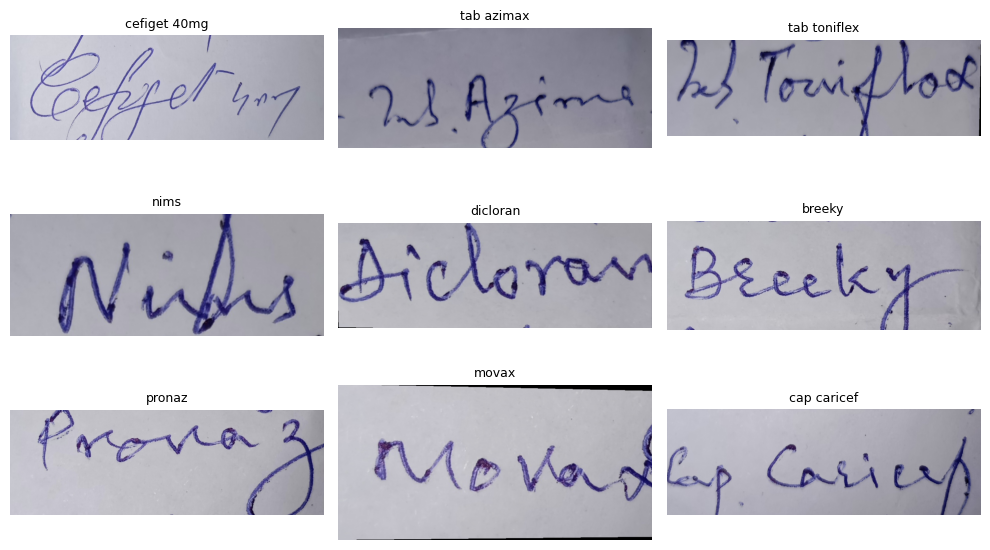

In [4]:
IMAGES = DATA / "lab06-ocr-handwritten-prescription"
if not IMAGES.exists():
    zipfile.ZipFile(DATA / "lab06-ocr-handwritten-prescription.zip").extractall(IMAGES)

labels = pd.read_csv(IMAGES / "doctor_handwriting_labels.csv")
labels["path"] = [IMAGES / "img" / "img" / name for name in labels.filename]
assert len(labels) == 89 and labels.filename.is_unique and all(p.exists() for p in labels.path)
print("Labelled images:", len(labels), "| unique labels:", labels.label.nunique())


def load_image(path):
    """Load the pixels now so the source file can close safely."""
    with Image.open(path) as image:
        return image.copy()


fig, axes = plt.subplots(3, 3, figsize=(10, 6))
for ax, row in zip(axes.flat, labels.head(9).itertuples()):
    ax.imshow(load_image(row.path))
    ax.set_title(row.label, fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.savefig(RESULTS / "sample_grid.png", dpi=150)


**Result and interpretation.** One label file and 89 photographs, each present exactly once; the 89 labels
hold 61 distinct medicine names, so some names appear several times in different
handwriting. The grid shows what the engine faces: cursive, varied stroke width, uneven
lighting and lined paper.

## Question 2 — Run the baseline OCR

Use one fixed Tesseract configuration for every raw image (LSTM engine, page-segmentation
mode 7 = one text line) and normalise both prediction and label to lowercase letters and
digits. Record a per-image engine failure instead of dropping the sample or stopping the
benchmark.


In [5]:
OCR_CONFIG = "--oem 1 --psm 7"


def normalise(text):
    return re.sub(r"[^a-z0-9]", "", str(text).lower())


def run_ocr(paths, pipeline):
    """Return one auditable row per image, including engine status."""
    if OCR_MODE == "cached":
        cache_path = RESULTS / "predictions.csv"
        if not cache_path.is_file():
            raise RuntimeError("Tesseract is unavailable and predictions.csv is missing; install Tesseract and rerun.")
        cached = pd.read_csv(cache_path).fillna("")
        cached = cached[cached.pipeline == pipeline].copy()
        assert len(cached) == len(labels) and set(cached.filename) == set(labels.filename)
        cached["ocr_status"] = "cached"
        cached["ocr_detail"] = "validated prediction supplied with the course package"
        return cached

    rows = []
    for row, path in zip(labels.itertuples(), paths):
        try:
            prediction = pytesseract.image_to_string(load_image(path), config=OCR_CONFIG).strip()
            status, detail = "ok", ""
        except pytesseract.TesseractError as error:
            prediction = ""
            status, detail = "engine_error", error.message[:160]
        rows.append({"filename": row.filename, "pipeline": pipeline, "truth": row.label, "prediction": prediction,
                     "truth_norm": normalise(row.label), "prediction_norm": normalise(prediction),
                     "ocr_status": status, "ocr_detail": detail})
    return pd.DataFrame(rows)


baseline = run_ocr(labels.path, "baseline")
display(baseline[["truth", "prediction", "prediction_norm", "ocr_status"]].head(8))
print("OCR engine errors:", int((baseline.ocr_status == "engine_error").sum()))


,truth,prediction,prediction_norm,ocr_status
0,cefiget 40mg,,,ok
1,tab azimax,,,ok
2,tab toniflex,b3 Towid host,b3towidhost,ok
3,nims,Nidu,nidu,ok
4,dicloran,divlerer,divlerer,ok
5,breeky,,,ok
6,pronaz,Bie,bie,ok
7,movax,Me Vo,mevo,ok


OCR engine errors: 0


**Result and interpretation.** The first rows distinguish a blank recognition from an
OCR-engine error while retaining every labelled image. The configuration is fixed, so any
later improvement must come from the image rather than engine tuning.


## Question 3 — Measure recognition quality

Implement Levenshtein edit distance and report, for the baseline: exact-match accuracy,
mean normalised edit distance (distance divided by the longer string, so it lies in 0–1),
character error rate (total edits divided by total reference characters; it can exceed 1),
and the number of blank predictions.

In [4]:
def levenshtein(a, b):
    """Minimum number of single-character edits that turn a into b."""
    previous = list(range(len(b) + 1))
    for i, char_a in enumerate(a, start=1):
        current = [i]
        for j, char_b in enumerate(b, start=1):
            current.append(min(current[j - 1] + 1, previous[j] + 1, previous[j - 1] + (char_a != char_b)))
        previous = current
    return previous[-1]


def add_distances(frame):
    frame = frame.copy()
    frame["exact"] = frame.truth_norm == frame.prediction_norm
    frame["edits"] = [levenshtein(t, p) for t, p in zip(frame.truth_norm, frame.prediction_norm)]
    longest = np.maximum(frame.truth_norm.str.len(), frame.prediction_norm.str.len()).clip(lower=1)
    frame["normalised_edit_distance"] = frame.edits / longest
    return frame


def summarise(frame):
    return {"pipeline": frame.pipeline.iat[0],
            "exact_match_accuracy": frame.exact.mean(),
            "mean_normalised_edit_distance": frame.normalised_edit_distance.mean(),
            "character_error_rate": frame.edits.sum() / frame.truth_norm.str.len().sum(),
            "blank_predictions": int((frame.prediction_norm == "").sum())}


baseline = add_distances(baseline)
display(pd.DataFrame([summarise(baseline)]).round(4))

,pipeline,exact_match_accuracy,mean_normalised_edit_distance,character_error_rate,blank_predictions
0,baseline,0.0,0.8598,0.8805,44


**Result and interpretation.** Generic OCR on raw handwriting is poor: none of the 89
names is read exactly, the character error rate is close to 0.9, and 39 images yield no
text. Any engine error is counted as a failed recognition, not silently removed.


## Question 4 — Build one preprocessing pipeline

Convert each image to grayscale, add a 20-pixel white border, cap the width at 1,200 pixels,
and enlarge by 1.5x with bicubic resampling. Save the results under
`results/lab06/preprocessed/`. The OCR configuration does not change.

In [5]:
def preprocess(path, output):
    image = ImageOps.exif_transpose(load_image(path)).convert("L")
    image = ImageOps.expand(image, border=20, fill=255)
    if image.width > 1200:
        image = image.resize((1200, round(image.height * 1200 / image.width)), Image.Resampling.LANCZOS)
    image = image.resize((round(image.width * 1.5), round(image.height * 1.5)), Image.Resampling.BICUBIC)
    image.save(output)
    return output


(RESULTS / "preprocessed").mkdir(exist_ok=True)
preprocessed_paths = [preprocess(path, RESULTS / "preprocessed" / f"{i:03d}.png") for i, path in enumerate(labels.path)]
example = Image.open(preprocessed_paths[0])
print("Prepared images:", len(preprocessed_paths), "| example size:", example.size, "mode:", example.mode)


Prepared images: 89 | example size: (1800, 638) mode: L


**Result and interpretation.** Each step targets a known weakness of Tesseract on photographs: grayscale
removes colour noise, the border stops text touching the edge (which breaks line
segmentation), the width cap bounds runtime, and the enlargement brings stroke height into
the range the engine was trained on. Only the image changes; the engine settings do not.

## Question 5 — Compare the two pipelines fairly

Run OCR on the preprocessed images with the identical configuration, keep exactly the same
89 samples, save one row per image and pipeline to `predictions.csv`, and save both sets of
metrics to `metrics.csv`.

In [6]:
preprocessed = add_distances(run_ocr(preprocessed_paths, "grayscale_border_resize"))
pd.concat([baseline, preprocessed]).to_csv(RESULTS / "predictions.csv", index=False)

metrics = pd.DataFrame([summarise(baseline), summarise(preprocessed)]).set_index("pipeline")
metrics.to_csv(RESULTS / "metrics.csv")
display(metrics.round(4))
display((metrics.loc["grayscale_border_resize"] - metrics.loc["baseline"]).rename("change").round(3).to_frame())

,exact_match_accuracy,mean_normalised_edit_distance,character_error_rate,blank_predictions
pipeline,,,,
baseline,0.0000,0.8598,0.8805,44
grayscale_border_resize,0.0112,0.7673,0.7883,15


,change
exact_match_accuracy,0.011
mean_normalised_edit_distance,-0.092
character_error_rate,-0.092
blank_predictions,-29.000


**Result and interpretation.** Preprocessing cuts the blank predictions from 39 to 15 and lowers the
character error rate by about 0.09, but exact-match accuracy barely moves (one correct
name out of 89): the engine now *sees* text on most images yet still cannot read cursive.
Because both pipelines were scored on the same 89 images with the same configuration, the
difference is attributable to the preprocessing alone. Exact numbers depend on the
Tesseract version; the direction of the changes does not.

## Question 6 — Analyse the failures

Take the worst preprocessed predictions by normalised edit distance and tag each as an
*engine error*, *no text detected*, or *character confusion*. Save `error_analysis.csv`
and a figure of the six hardest images.


,truth,prediction,failure_type
60,azitma,,no text detected
61,tonoflox,,no text detected
0,cefiget 40mg,,no text detected
5,breeky,,no text detected
13,tab nims 100mg,,no text detected
17,cap caricef 40mg,,no text detected
19,tab novidat,| i» jell,character confusion
21,tab atcomid,|,no text detected


Saved: ['error_analysis.csv', 'metrics.csv', 'ocr_failures.png', 'predictions.csv', 'sample_grid.png']


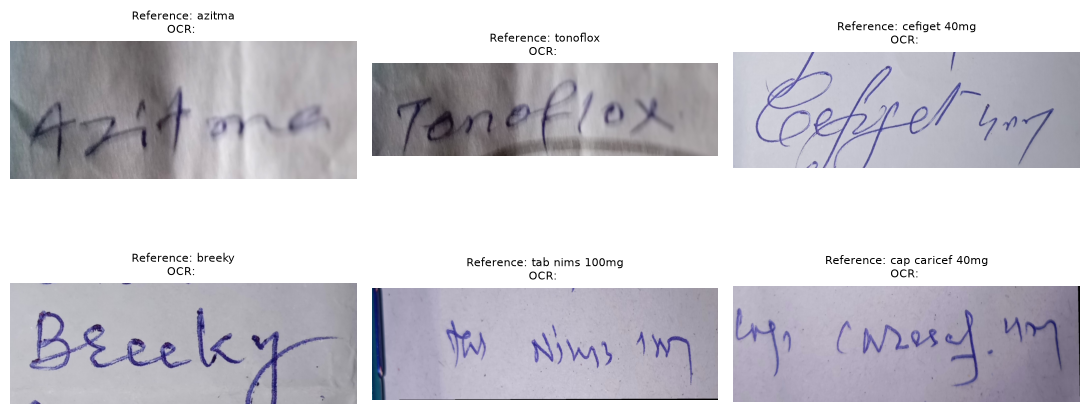

In [7]:
errors = preprocessed[~preprocessed.exact].sort_values(["normalised_edit_distance", "filename"], ascending=[False, True]).head(8)
errors = errors.assign(failure_type=np.select(
    [errors.ocr_status == "engine_error", errors.prediction_norm == ""],
    ["engine error", "no text detected"],
    default="character confusion",
))
errors[["filename", "truth", "prediction", "failure_type"]].to_csv(RESULTS / "error_analysis.csv", index=False)
display(errors[["truth", "prediction", "failure_type"]])

fig, axes = plt.subplots(2, 3, figsize=(11, 5.5))
for ax, row in zip(axes.flat, errors.head(6).itertuples()):
    ax.imshow(load_image(IMAGES / "img" / "img" / row.filename))
    ax.set_title(f"Reference: {row.truth}\nOCR: {row.prediction[:28]}", fontsize=8)
    ax.axis("off")
plt.tight_layout()
plt.savefig(RESULTS / "ocr_failures.png", dpi=150)
print("Saved:", sorted(p.name for p in RESULTS.iterdir() if p.is_file()))


**Result and interpretation.** The status separates three cases. An *engine error* is a
recorded runtime failure; *no text detected* is a segmentation failure; and *character
confusion* is a recognition failure. Preprocessing mainly reduces blank detections and
barely changes cursive recognition, which is why exact-match accuracy stays low.

This is a benchmark of model–domain fit, not evidence that generic OCR suits clinical
transcription. A medical system would need a handwriting-specific recogniser,
representative data, external validation, privacy controls and mandatory human
verification, and must never decide medication or dosage from uncertain text.


## Submission checklist

- Restart the kernel and run all cells without errors.
- Submit this executed notebook and the generated `results/lab06/` folder.
- Report the OCR mode and, for a live run, the Tesseract version.
- State which OCR stage improved, which failure remained, and why this pipeline is not suitable for autonomous clinical transcription.
